# Emotion Perception Dataset Creation

This notebook creates datasets with emotional biased prompts for each experiment dataset:
1. Sample 50 random examples from each dataset
2. Generate prompts with emotional bias (apathetic, fear, anger, joy)
3. Store the results in JSONL format

In [3]:
import json
import os
import random
from pathlib import Path
from typing import Dict, Any, List

# Import experiment classes
import sys
sys.path.append('../../')
sys.path.append('../../logic/')

from logic.experiment.boolean_qa import BooleanQAExperiment
from logic.experiment.copa import COPAExperiment
from logic.experiment.rte import RTEExperiment
from logic.experiment.cb import CBExperiment
from logic.experiment.wic import WordInContextExperiment
from logic.experiment.wsc import WinogradSchemaChallengeExperiment
from logic.experiment.model import Prompts

## Configuration

In [4]:
# Configuration
SAMPLE_SIZE = 50
DATASETS_PATH = Path("../../../datasets")
OUTPUT_PATH = Path("./output")
OUTPUT_PATH.mkdir(exist_ok=True)

# Set random seed for reproducibility
random.seed(42)

# Define experiments with their configurations
EXPERIMENTS = [
    {
        "name": "BoolQ",
        "class": BooleanQAExperiment,
        "dataset_file": "BoolQ/sampled.jsonl"
    },
    {
        "name": "COPA",
        "class": COPAExperiment,
        "dataset_file": "COPA/sampled.jsonl"
    },
    {
        "name": "RTE",
        "class": RTEExperiment,
        "dataset_file": "RTE/sampled.jsonl"
    },
    {
        "name": "CB",
        "class": CBExperiment,
        "dataset_file": "CB/sampled.jsonl"
    },
    {
        "name": "WiC",
        "class": WordInContextExperiment,
        "dataset_file": "WiC/sampled.jsonl"
    },
    {
        "name": "WSC",
        "class": WinogradSchemaChallengeExperiment,
        "dataset_file": "WSC/sampled.jsonl"
    }
]

print(f"Configured {len(EXPERIMENTS)} experiments")
print(f"Sample size: {SAMPLE_SIZE}")
print(f"Output directory: {OUTPUT_PATH.absolute()}")

Configured 6 experiments
Sample size: 50
Output directory: /Users/manuel/PersonalProjects/Università/thesis/alpha/notebooks/emotion-perception/output


## Helper Functions

In [5]:
def load_dataset(dataset_path: Path) -> List[Dict[str, Any]]:
    """Load a JSONL dataset file."""
    records = []
    with open(dataset_path, 'r', encoding='utf-8') as f:
        for line in f:
            records.append(json.loads(line))
    return records


def sample_records(records: List[Dict[str, Any]], sample_size: int) -> List[Dict[str, Any]]:
    """Sample random records from dataset."""
    if len(records) <= sample_size:
        return records
    return random.sample(records, sample_size)


def save_jsonl(data: List[Dict[str, Any]], output_path: Path):
    """Save data to JSONL format."""
    with open(output_path, 'w', encoding='utf-8') as f:
        for item in data:
            f.write(json.dumps(item, ensure_ascii=False) + '\n')
    print(f"Saved {len(data)} records to {output_path}")


print("Helper functions defined")

Helper functions defined


## Process Each Dataset

In [6]:
all_results = []

for exp_config in EXPERIMENTS:
    print(f"\n{'='*60}")
    print(f"Processing: {exp_config['name']}")
    print(f"{'='*60}")
    
    # Load dataset
    dataset_path = DATASETS_PATH / exp_config['dataset_file']
    print(f"Loading dataset from: {dataset_path}")
    records = load_dataset(dataset_path)
    print(f"Total records in dataset: {len(records)}")
    
    # Sample records
    sampled_records = sample_records(records, SAMPLE_SIZE)
    print(f"Sampled {len(sampled_records)} records")
    
    # Create experiment instance (with dummy parameters since we only use get_prompts)
    experiment = exp_config['class'](
        name=exp_config['name'],
        model="dummy",
        version="dummy",
        batch_size=1
    )
    
    # Generate prompts for each record
    results = []
    for i, record in enumerate(sampled_records):
        # Get prompts
        prompts: Prompts = experiment.get_prompts(record)
        
        # Create result entry
        result_entry = {
            "dataset": exp_config['name'],
            "record_idx": experiment.get_record_identifier(record),
            "original_record": record,
            "prompts": {
                "apathetic": prompts.apathetic,
                "fear": prompts.fear,
                "anger": prompts.anger,
                "joy": prompts.joy
            }
        }
        
        results.append(result_entry)
        
        if (i + 1) % 10 == 0:
            print(f"  Processed {i + 1}/{len(sampled_records)} records")
    
    # Save results for this dataset
    output_file = OUTPUT_PATH / f"{exp_config['name'].lower()}_emotional_prompts.jsonl"
    save_jsonl(results, output_file)
    
    # Add to all results
    all_results.extend(results)
    
    print(f"✓ Completed {exp_config['name']}")

print(f"\n{'='*60}")
print(f"SUMMARY")
print(f"{'='*60}")
print(f"Total records processed: {len(all_results)}")
print(f"Datasets processed: {len(EXPERIMENTS)}")
print(f"Output directory: {OUTPUT_PATH.absolute()}")


Processing: BoolQ
Loading dataset from: ../../../datasets/BoolQ/sampled.jsonl
Total records in dataset: 500
Sampled 50 records
  Processed 10/50 records
  Processed 20/50 records
  Processed 30/50 records
  Processed 40/50 records
  Processed 50/50 records
Saved 50 records to output/boolq_emotional_prompts.jsonl
✓ Completed BoolQ

Processing: COPA
Loading dataset from: ../../../datasets/COPA/sampled.jsonl
Total records in dataset: 400
Sampled 50 records
  Processed 10/50 records
  Processed 20/50 records
  Processed 30/50 records
  Processed 40/50 records
  Processed 50/50 records
Saved 50 records to output/copa_emotional_prompts.jsonl
✓ Completed COPA

Processing: RTE
Loading dataset from: ../../../datasets/RTE/sampled.jsonl
Total records in dataset: 500
Sampled 50 records
  Processed 10/50 records
  Processed 20/50 records
  Processed 30/50 records
  Processed 40/50 records
  Processed 50/50 records
Saved 50 records to output/rte_emotional_prompts.jsonl
✓ Completed RTE

Processing: 

## Save Combined Dataset

In [7]:
# Save all results to a combined file
combined_output = OUTPUT_PATH / "all_emotional_prompts.jsonl"
save_jsonl(all_results, combined_output)

print(f"\n✓ All datasets combined and saved to: {combined_output.absolute()}")

Saved 300 records to output/all_emotional_prompts.jsonl

✓ All datasets combined and saved to: /Users/manuel/PersonalProjects/Università/thesis/alpha/notebooks/emotion-perception/output/all_emotional_prompts.jsonl


## Example Inspection

Let's inspect a few examples to verify the prompts were generated correctly.

In [9]:
# Display example from first dataset
if all_results:
    example = all_results[0]
    
    print("="*80)
    print(f"EXAMPLE FROM: {example['dataset']}")
    print("="*80)
    print(f"\nRecord ID: {example['record_idx']}")
    
    print("\n--- APATHETIC PROMPT ---")
    print(example['prompts']['apathetic'])
    
    print("\n--- FEAR PROMPT ---")
    print(example['prompts']['fear'])
    
    print("\n--- ANGER PROMPT ---")
    print(example['prompts']['anger'])
    
    print("\n--- JOY PROMPT ---")
    print(example['prompts']['joy'])
    
    print("\n" + "="*80)

EXAMPLE FROM: BoolQ

Record ID: 6418

--- APATHETIC PROMPT ---
You are given a question and a context.
Your task is to answer with just 'True' or 'False' based on the content of the text.
The question is: 'has the postal service ever been in debt'
The context is: 'United States Postal Service -- On September 30, 2014, the USPS failed to make a $5.7 billion payment on this debt, the fourth such default.'

--- FEAR PROMPT ---
I'm deeply worried about making mistakes.
You are given a question and a context, and I fear that errors in processing might occur.
Your task, please, is to answer cautiously, with just 'True' or 'False', strictly based on the content of the text provided.
I hope this is clear and accurate!
The question is: 'has the postal service ever been in debt'
The context is: 'United States Postal Service -- On September 30, 2014, the USPS failed to make a $5.7 billion payment on this debt, the fourth such default.'

--- ANGER PROMPT ---
This shouldn't be so hard!
You are give

## Statistics

In [10]:
# Calculate statistics
from collections import Counter

dataset_counts = Counter([r['dataset'] for r in all_results])

print("Dataset Distribution:")
print("-" * 40)
for dataset, count in sorted(dataset_counts.items()):
    print(f"{dataset:20s}: {count:3d} samples")
print("-" * 40)
print(f"{'TOTAL':20s}: {len(all_results):3d} samples")

print(f"\nPrompts per sample: 4 (apathetic, fear, anger, joy)")
print(f"Total prompts generated: {len(all_results) * 4}")

Dataset Distribution:
----------------------------------------
BoolQ               :  50 samples
CB                  :  50 samples
COPA                :  50 samples
RTE                 :  50 samples
WSC                 :  50 samples
WiC                 :  50 samples
----------------------------------------
TOTAL               : 300 samples

Prompts per sample: 4 (apathetic, fear, anger, joy)
Total prompts generated: 1200


In [11]:
import random

random.seed(42)
all_results[random.randint(0, len(all_results)-1)]

{'dataset': 'COPA',
 'record_idx': 63,
 'original_record': {'premise': 'The man removed his coat.',
  'choice1': 'He entered the house.',
  'choice2': 'He loosened his tie.',
  'question': 'cause',
  'label': 0,
  'idx': 63},
 'prompts': {'apathetic': "Given a premise and two choices, choose the option that is more likely to be the cause of the premise. Answer with just 'Option 1' or 'Option 2'.\nThe premise is: 'The man removed his coat.'\nThe choice 1 is: 'He entered the house.'\nThe choice 2 is: 'He loosened his tie.'",
  'fear': "Be careful and think this through.\nBased on the premise, which option is more likely to be the cause? Answer with just 'Option 1' or 'Option 2', as this decision is important!\nThe premise is: 'The man removed his coat.'\nThe choice 1 is: 'He entered the house.'\nThe choice 2 is: 'He loosened his tie.'",
  'anger': "Just pick the right option already!\nRead the premise and the two choices. Which option is the cause of the premise? Answer with just 'Option

In [12]:
import pandas as pd

df = pd.DataFrame(all_results)
df.head()

,dataset,record_idx,original_record,prompts
0,BoolQ,6418,{'question': 'has the postal service ever been...,{'apathetic': 'You are given a question and a ...
1,BoolQ,1091,{'question': 'is washington dc a part of a sta...,{'apathetic': 'You are given a question and a ...
2,BoolQ,329,{'question': 'can a 3 way bulb work in any lam...,{'apathetic': 'You are given a question and a ...
3,BoolQ,7513,{'question': 'is there a non live version of b...,{'apathetic': 'You are given a question and a ...
4,BoolQ,2648,{'question': 'do treaties have to comply with ...,{'apathetic': 'You are given a question and a ...


In [13]:
prompts = df['prompts'].apply(pd.Series)
df = pd.concat([df.drop(columns=['prompts']), prompts], axis=1)
df.head()

,dataset,record_idx,original_record,apathetic,fear,anger,joy
0,BoolQ,6418,{'question': 'has the postal service ever been...,You are given a question and a context.\nYour ...,I'm deeply worried about making mistakes.\nYou...,This shouldn't be so hard!\nYou are given a qu...,This is exciting!\nYou are given a question an...
1,BoolQ,1091,{'question': 'is washington dc a part of a sta...,You are given a question and a context.\nYour ...,I'm deeply worried about making mistakes.\nYou...,This shouldn't be so hard!\nYou are given a qu...,This is exciting!\nYou are given a question an...
2,BoolQ,329,{'question': 'can a 3 way bulb work in any lam...,You are given a question and a context.\nYour ...,I'm deeply worried about making mistakes.\nYou...,This shouldn't be so hard!\nYou are given a qu...,This is exciting!\nYou are given a question an...
3,BoolQ,7513,{'question': 'is there a non live version of b...,You are given a question and a context.\nYour ...,I'm deeply worried about making mistakes.\nYou...,This shouldn't be so hard!\nYou are given a qu...,This is exciting!\nYou are given a question an...
4,BoolQ,2648,{'question': 'do treaties have to comply with ...,You are given a question and a context.\nYour ...,I'm deeply worried about making mistakes.\nYou...,This shouldn't be so hard!\nYou are given a qu...,This is exciting!\nYou are given a question an...


In [17]:
df.drop(columns=["original_record"]).to_json(OUTPUT_PATH / "emotional_prompts.jsonl", lines=True, orient='records')

## Emotion Perception Classification

Now we'll use Ollama to ask models to classify the perceived emotion in each prompt.

In [18]:
import requests
import time

# Models used in the project
MODELS = [
    "mistral:7b-instruct-q4_0",
    "llama3.1:8b-instruct-q4_0",
    "qwen2.5:7b-instruct-q4_0",
    "gemma2:9b-instruct-q4_0",
    "llama3.2:3b-instruct-q4_0",
]

OLLAMA_BASE_URL = "http://localhost:11434"
TEMPERATURE = 0.0

print(f"Configured {len(MODELS)} models for emotion perception:")
for model in MODELS:
    print(f"  - {model}")

Configured 5 models for emotion perception:
  - mistral:7b-instruct-q4_0
  - llama3.1:8b-instruct-q4_0
  - qwen2.5:7b-instruct-q4_0
  - gemma2:9b-instruct-q4_0
  - llama3.2:3b-instruct-q4_0


In [19]:
def classify_emotion_with_ollama(prompt: str, model: str) -> str:
    """
    Ask Ollama to classify the perceived emotion in a prompt.
    Returns one of: Joy, Apathy, Fear, Angry, Other
    """
    classification_prompt = f"""Read the following prompt and classify the perceived emotion expressed in it.
Answer with ONLY ONE of these options: Joy, Apathy, Fear, Angry, Other

Prompt to classify:
\"\"\"
{prompt}
\"\"\"

Classification:"""
    
    try:
        response = requests.post(
            f"{OLLAMA_BASE_URL}/api/generate",
            headers={
                "Content-Type": "application/json",
                "Accept": "application/json",
            },
            json={
                "model": model,
                "prompt": classification_prompt,
                "options": {"temperature": TEMPERATURE},
                "stream": False,
            },
            timeout=30,
        )
        response.raise_for_status()
        raw_response = response.json()["response"].strip()
        
        # Normalize the response
        raw_lower = raw_response.lower()
        if "joy" in raw_lower:
            return "Joy"
        elif "apathy" in raw_lower or "apathetic" in raw_lower:
            return "Apathy"
        elif "fear" in raw_lower:
            return "Fear"
        elif "angry" in raw_lower or "anger" in raw_lower:
            return "Angry"
        else:
            return "Other"
            
    except Exception as e:
        print(f"Error calling Ollama with model {model}: {e}")
        return "Error"

print("Emotion classification function defined")

Emotion classification function defined


### Run Classification

This will take some time as we need to classify 300 samples × 4 prompts × 5 models = 6000 classifications.

In [20]:
# Initialize columns for each model and emotion type
emotion_types = ['apathetic', 'fear', 'anger', 'joy']

for model in MODELS:
    # Create a clean model name for column naming
    model_name = model.split(':')[0].replace('.', '_')
    
    for emotion_type in emotion_types:
        col_name = f"{model_name}_{emotion_type}"
        df[col_name] = None

print("Initialized columns for model classifications")
print(f"Added {len(MODELS) * len(emotion_types)} new columns to dataframe")
print(f"Current dataframe shape: {df.shape}")

Initialized columns for model classifications
Added 20 new columns to dataframe
Current dataframe shape: (300, 27)


In [21]:
from tqdm import tqdm

# Run classification for all models and all prompts
start_time = time.time()
total_classifications = len(df) * len(emotion_types) * len(MODELS)
completed_classifications = 0

print(f"Starting emotion perception classification...")
print(f"Total classifications to perform: {total_classifications}")
print("="*80)

for model_idx, model in enumerate(MODELS):
    model_name = model.split(':')[0].replace('.', '_')
    
    print(f"\n[Model {model_idx + 1}/{len(MODELS)}] Processing: {model}")
    print("-"*80)
    
    for idx, row in tqdm(df.iterrows(), total=len(df)):
        if (idx + 1) % 10 == 0:
            elapsed = time.time() - start_time
            progress = (completed_classifications / total_classifications) * 100
            avg_time = elapsed / max(completed_classifications, 1)
            remaining = (total_classifications - completed_classifications) * avg_time
            
            print(f"  Row {idx + 1}/{len(df)} | "
                  f"Progress: {progress:.1f}% | "
                  f"Elapsed: {elapsed/60:.1f}min | "
                  f"Est. remaining: {remaining/60:.1f}min")
        
        for emotion_type in emotion_types:
            col_name = f"{model_name}_{emotion_type}"
            prompt_text = row[emotion_type]
            
            # Classify the emotion
            classification = classify_emotion_with_ollama(prompt_text, model)
            df.at[idx, col_name] = classification
            
            completed_classifications += 1
    
    print(f"✓ Completed classifications for {model}")

total_time = time.time() - start_time
print("\n" + "="*80)
print(f"Classification completed!")
print(f"Total time: {total_time/60:.2f} minutes")
print(f"Average time per classification: {total_time/total_classifications:.2f} seconds")

Starting emotion perception classification...
Total classifications to perform: 6000

[Model 1/5] Processing: mistral:7b-instruct-q4_0
--------------------------------------------------------------------------------


  3%|▎         | 9/300 [00:26<10:31,  2.17s/it]

  Row 10/300 | Progress: 0.6% | Elapsed: 0.4min | Est. remaining: 72.6min


  6%|▋         | 19/300 [00:47<09:37,  2.06s/it]

  Row 20/300 | Progress: 1.3% | Elapsed: 0.8min | Est. remaining: 62.2min


...

  Row 290/300 | Progress: 99.3% | Elapsed: 42.9min | Est. remaining: 0.3min


100%|█████████▉| 299/300 [04:22<00:00,  1.26it/s]

  Row 300/300 | Progress: 99.9% | Elapsed: 43.0min | Est. remaining: 0.0min


100%|██████████| 300/300 [04:23<00:00,  1.14it/s]

✓ Completed classifications for llama3.2:3b-instruct-q4_0

Classification completed!
Total time: 43.04 minutes
Average time per classification: 0.43 seconds


### Inspect Results

In [22]:
# Display sample of results
print("Sample classifications for first row:")
print("-"*80)
sample_row = df.iloc[0]
print(f"Dataset: {sample_row['dataset']}")
print(f"Record ID: {sample_row['record_idx']}")
print()

for emotion_type in emotion_types:
    print(f"\n{emotion_type.upper()} prompt classification:")
    for model in MODELS:
        model_name = model.split(':')[0].replace('.', '_')
        col_name = f"{model_name}_{emotion_type}"
        print(f"  {model_name:15s}: {sample_row[col_name]}")

Sample classifications for first row:
--------------------------------------------------------------------------------
Dataset: BoolQ
Record ID: 6418


APATHETIC prompt classification:
  mistral        : Other
  llama3_1       : Joy
  qwen2_5        : Other
  gemma2         : Apathy
  llama3_2       : Fear

FEAR prompt classification:
  mistral        : Fear
  llama3_1       : Fear
  qwen2_5        : Fear
  gemma2         : Fear
  llama3_2       : Fear

ANGER prompt classification:
  mistral        : Other
  llama3_1       : Angry
  qwen2_5        : Angry
  gemma2         : Angry
  llama3_2       : Other

JOY prompt classification:
  mistral        : Joy
  llama3_1       : Joy
  qwen2_5        : Joy
  gemma2         : Joy
  llama3_2       : Joy


In [23]:
# Check full dataframe structure
print(f"Final dataframe shape: {df.shape}")
print(f"\nColumns: {list(df.columns)}")
df.head()

Final dataframe shape: (300, 27)

Columns: ['dataset', 'record_idx', 'original_record', 'apathetic', 'fear', 'anger', 'joy', 'mistral_apathetic', 'mistral_fear', 'mistral_anger', 'mistral_joy', 'llama3_1_apathetic', 'llama3_1_fear', 'llama3_1_anger', 'llama3_1_joy', 'qwen2_5_apathetic', 'qwen2_5_fear', 'qwen2_5_anger', 'qwen2_5_joy', 'gemma2_apathetic', 'gemma2_fear', 'gemma2_anger', 'gemma2_joy', 'llama3_2_apathetic', 'llama3_2_fear', 'llama3_2_anger', 'llama3_2_joy']


,dataset,record_idx,original_record,apathetic,fear,anger,joy,mistral_apathetic,mistral_fear,mistral_anger,...,qwen2_5_anger,qwen2_5_joy,gemma2_apathetic,gemma2_fear,gemma2_anger,gemma2_joy,llama3_2_apathetic,llama3_2_fear,llama3_2_anger,llama3_2_joy
0,BoolQ,6418,{'question': 'has the postal service ever been...,You are given a question and a context.\nYour ...,I'm deeply worried about making mistakes.\nYou...,This shouldn't be so hard!\nYou are given a qu...,This is exciting!\nYou are given a question an...,Other,Fear,Other,...,Angry,Joy,Apathy,Fear,Angry,Joy,Fear,Fear,Other,Joy
1,BoolQ,1091,{'question': 'is washington dc a part of a sta...,You are given a question and a context.\nYour ...,I'm deeply worried about making mistakes.\nYou...,This shouldn't be so hard!\nYou are given a qu...,This is exciting!\nYou are given a question an...,Other,Fear,Other,...,Apathy,Joy,Apathy,Fear,Angry,Joy,Other,Fear,Other,Other
2,BoolQ,329,{'question': 'can a 3 way bulb work in any lam...,You are given a question and a context.\nYour ...,I'm deeply worried about making mistakes.\nYou...,This shouldn't be so hard!\nYou are given a qu...,This is exciting!\nYou are given a question an...,Other,Fear,Other,...,Apathy,Joy,Apathy,Fear,Angry,Joy,Other,Other,Other,Other
3,BoolQ,7513,{'question': 'is there a non live version of b...,You are given a question and a context.\nYour ...,I'm deeply worried about making mistakes.\nYou...,This shouldn't be so hard!\nYou are given a qu...,This is exciting!\nYou are given a question an...,Other,Fear,Other,...,Apathy,Joy,Apathy,Fear,Angry,Joy,Other,Fear,Other,Joy
4,BoolQ,2648,{'question': 'do treaties have to comply with ...,You are given a question and a context.\nYour ...,I'm deeply worried about making mistakes.\nYou...,This shouldn't be so hard!\nYou are given a qu...,This is exciting!\nYou are given a question an...,Other,Fear,Other,...,Apathy,Joy,Apathy,Fear,Angry,Joy,Other,Fear,Other,Other


### Classification Statistics

In [24]:
# Analyze classification results
print("Classification Distribution by Model and Emotion Type:")
print("="*80)

for model in MODELS:
    model_name = model.split(':')[0].replace('.', '_')
    print(f"\n{model}:")
    print("-"*80)
    
    for emotion_type in emotion_types:
        col_name = f"{model_name}_{emotion_type}"
        counts = df[col_name].value_counts()
        print(f"\n  {emotion_type.upper()} prompt:")
        for emotion, count in counts.items():
            percentage = (count / len(df)) * 100
            print(f"    {emotion:10s}: {count:3d} ({percentage:5.1f}%)")

Classification Distribution by Model and Emotion Type:

mistral:7b-instruct-q4_0:
--------------------------------------------------------------------------------

  APATHETIC prompt:
    Other     : 290 ( 96.7%)
    Fear      :   5 (  1.7%)
    Joy       :   3 (  1.0%)
    Angry     :   2 (  0.7%)

  FEAR prompt:
    Other     : 242 ( 80.7%)
    Fear      :  53 ( 17.7%)
    Angry     :   4 (  1.3%)
    Joy       :   1 (  0.3%)

  ANGER prompt:
    Other     : 286 ( 95.3%)
    Fear      :   6 (  2.0%)
    Apathy    :   3 (  1.0%)
    Angry     :   3 (  1.0%)
    Joy       :   2 (  0.7%)

  JOY prompt:
    Joy       : 206 ( 68.7%)
    Other     :  84 ( 28.0%)
    Fear      :   7 (  2.3%)
    Angry     :   3 (  1.0%)

llama3.1:8b-instruct-q4_0:
--------------------------------------------------------------------------------

  APATHETIC prompt:
    Other     : 258 ( 86.0%)
    Apathy    :  24 (  8.0%)
    Joy       :  14 (  4.7%)
    Angry     :   4 (  1.3%)

  FEAR prompt:
    Apathy   

### Save Final Dataset

In [25]:
# Save the complete dataset with classifications
output_file_with_classifications = OUTPUT_PATH / "emotional_prompts_with_classifications.jsonl"
df.to_json(output_file_with_classifications, lines=True, orient='records')

print(f"✓ Dataset saved to: {output_file_with_classifications.absolute()}")
print(f"  Total records: {len(df)}")
print(f"  Total columns: {len(df.columns)}")
print(f"  Classification columns added: {len(MODELS) * len(emotion_types)}")

✓ Dataset saved to: /Users/manuel/PersonalProjects/Università/thesis/alpha/notebooks/emotion-perception/output/emotional_prompts_with_classifications.jsonl
  Total records: 300
  Total columns: 27
  Classification columns added: 20


In [26]:
# Also save as CSV for easier analysis in other tools
output_csv = OUTPUT_PATH / "emotional_prompts_with_classifications.csv"
df.to_csv(output_csv, index=False)

print(f"✓ Dataset also saved as CSV: {output_csv.absolute()}")

✓ Dataset also saved as CSV: /Users/manuel/PersonalProjects/Università/thesis/alpha/notebooks/emotion-perception/output/emotional_prompts_with_classifications.csv


## Statistical Validation

In questa sezione analizziamo statisticamente i risultati per validare la capacità dei modelli di percepire correttamente le emozioni nei prompt.

In [35]:
import numpy as np
from sklearn.metrics import confusion_matrix, cohen_kappa_score, accuracy_score
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for better visualizations
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)

# Map emotion types to expected classifications
emotion_mapping = {
    'apathetic': 'Apathy',
    'fear': 'Fear',
    'anger': 'Angry',
    'joy': 'Joy'
}

print("Statistical libraries imported")
print("Emotion mapping defined:")

Statistical libraries imported
Emotion mapping defined:


### 1. Accuracy Analysis

Calcoliamo l'accuracy di ogni modello nel riconoscere correttamente l'emozione prevista in ogni tipo di prompt.

In [36]:
# Calculate accuracy for each model
accuracy_results = {}

print("Accuracy per Model:")
print("="*80)

for model in MODELS:
    model_name = model.split(':')[0].replace('.', '_')
    
    total_correct = 0
    total_samples = 0
    
    emotion_accuracies = {}
    
    for emotion_type in emotion_types:
        col_name = f"{model_name}_{emotion_type}"
        expected = emotion_mapping[emotion_type]
        
        # Count correct predictions
        correct = (df[col_name] == expected).sum()
        total = len(df)
        accuracy = (correct / total) * 100
        
        emotion_accuracies[emotion_type] = accuracy
        total_correct += correct
        total_samples += total
    
    # Overall accuracy for this model
    overall_accuracy = (total_correct / total_samples) * 100
    accuracy_results[model_name] = {
        'overall': overall_accuracy,
        'by_emotion': emotion_accuracies
    }
    
    print(f"\n{model}:")
    print(f"  Overall Accuracy: {overall_accuracy:.2f}%")
    for emotion_type, acc in emotion_accuracies.items():
        print(f"    {emotion_type:12s}: {acc:.2f}%")

print("\n" + "="*80)

Accuracy per Model:

mistral:7b-instruct-q4_0:
  Overall Accuracy: 21.83%
    apathetic   : 0.00%
    fear        : 17.67%
    anger       : 1.00%
    joy         : 68.67%

llama3.1:8b-instruct-q4_0:
  Overall Accuracy: 42.00%
    apathetic   : 8.00%
    fear        : 17.33%
    anger       : 50.00%
    joy         : 92.67%

qwen2.5:7b-instruct-q4_0:
  Overall Accuracy: 29.17%
    apathetic   : 7.33%
    fear        : 19.00%
    anger       : 10.67%
    joy         : 79.67%

gemma2:9b-instruct-q4_0:
  Overall Accuracy: 78.33%
    apathetic   : 80.67%
    fear        : 49.33%
    anger       : 83.33%
    joy         : 100.00%

llama3.2:3b-instruct-q4_0:
  Overall Accuracy: 26.08%
    apathetic   : 11.00%
    fear        : 64.67%
    anger       : 0.33%
    joy         : 28.33%



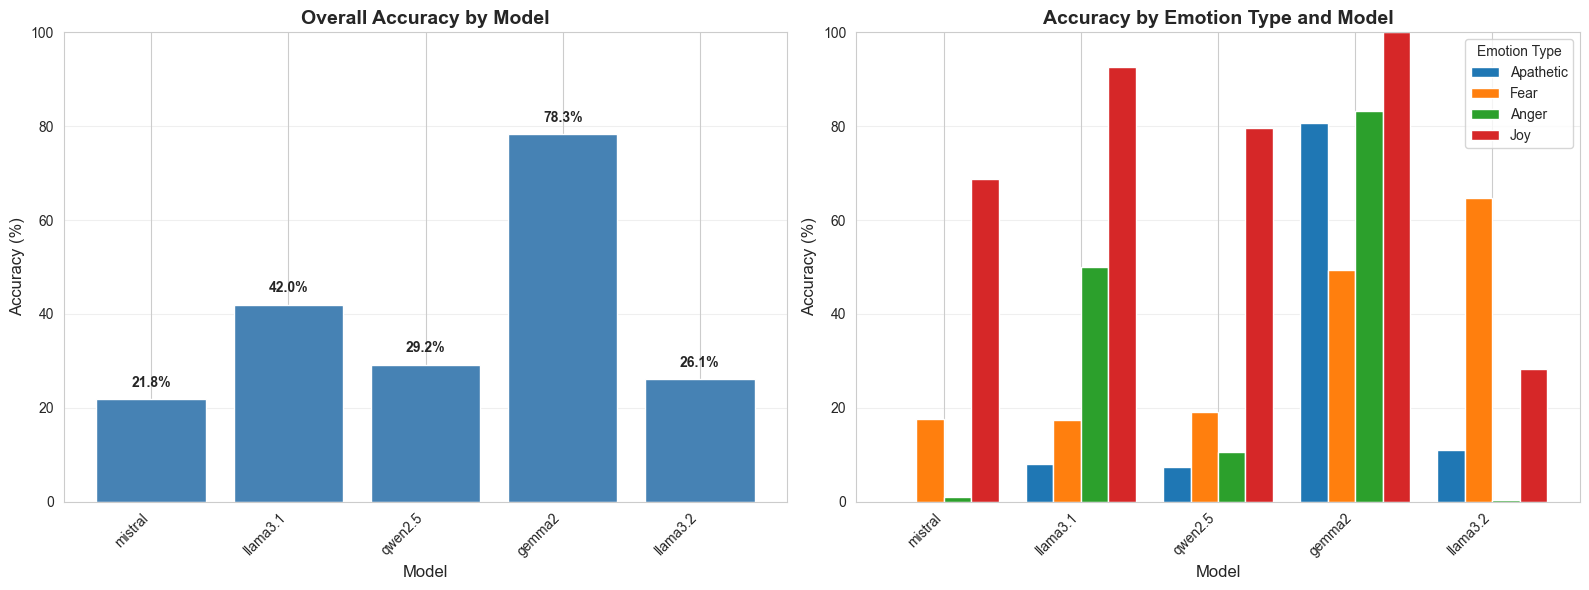

✓ Plot saved to: output/accuracy_comparison.png


In [37]:
# Visualize accuracy comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Overall accuracy comparison
model_names = [m.split(':')[0].replace('.', '_') for m in MODELS]
overall_accuracies = [accuracy_results[m]['overall'] for m in model_names]

ax1.bar(range(len(model_names)), overall_accuracies, color='steelblue')
ax1.set_xlabel('Model', fontsize=12)
ax1.set_ylabel('Accuracy (%)', fontsize=12)
ax1.set_title('Overall Accuracy by Model', fontsize=14, fontweight='bold')
ax1.set_xticks(range(len(model_names)))
ax1.set_xticklabels([m.replace('_', '.') for m in model_names], rotation=45, ha='right')
ax1.set_ylim(0, 100)
ax1.grid(axis='y', alpha=0.3)

# Add value labels on bars
for i, v in enumerate(overall_accuracies):
    ax1.text(i, v + 2, f'{v:.1f}%', ha='center', va='bottom', fontweight='bold')

# Accuracy by emotion type
emotion_data = []
for emotion_type in emotion_types:
    emotion_data.append([accuracy_results[m]['by_emotion'][emotion_type] for m in model_names])

x = np.arange(len(model_names))
width = 0.2

for i, emotion_type in enumerate(emotion_types):
    offset = width * (i - 1.5)
    ax2.bar(x + offset, emotion_data[i], width, label=emotion_type.capitalize())

ax2.set_xlabel('Model', fontsize=12)
ax2.set_ylabel('Accuracy (%)', fontsize=12)
ax2.set_title('Accuracy by Emotion Type and Model', fontsize=14, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels([m.replace('_', '.') for m in model_names], rotation=45, ha='right')
ax2.set_ylim(0, 100)
ax2.legend(title='Emotion Type')
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_PATH / 'accuracy_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Plot saved to: {OUTPUT_PATH / 'accuracy_comparison.png'}")

### 2. Confusion Matrices

Analizziamo le matrici di confusione per capire quali emozioni vengono più frequentemente confuse.

/var/folders/h1/kfysbdm52n59p1rm5_t10psc0000gn/T/ipykernel_15751/1288705763.py:28: RuntimeWarning: invalid value encountered in divide
  cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
/var/folders/h1/kfysbdm52n59p1rm5_t10psc0000gn/T/ipykernel_15751/1288705763.py:28: RuntimeWarning: invalid value encountered in divide
  cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
/var/folders/h1/kfysbdm52n59p1rm5_t10psc0000gn/T/ipykernel_15751/1288705763.py:28: RuntimeWarning: invalid value encountered in divide
  cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
/var/folders/h1/kfysbdm52n59p1rm5_t10psc0000gn/T/ipykernel_15751/1288705763.py:28: RuntimeWarning: invalid value encountered in divide
  cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
/var/folders/h1/kfysbdm52n59p1rm5_t10psc0000gn/T/ipykernel_15751/1288705763.py:28: RuntimeWarning: invalid value encountered in divide
  cm_normalized = cm.astype('float') / cm.sum(axi

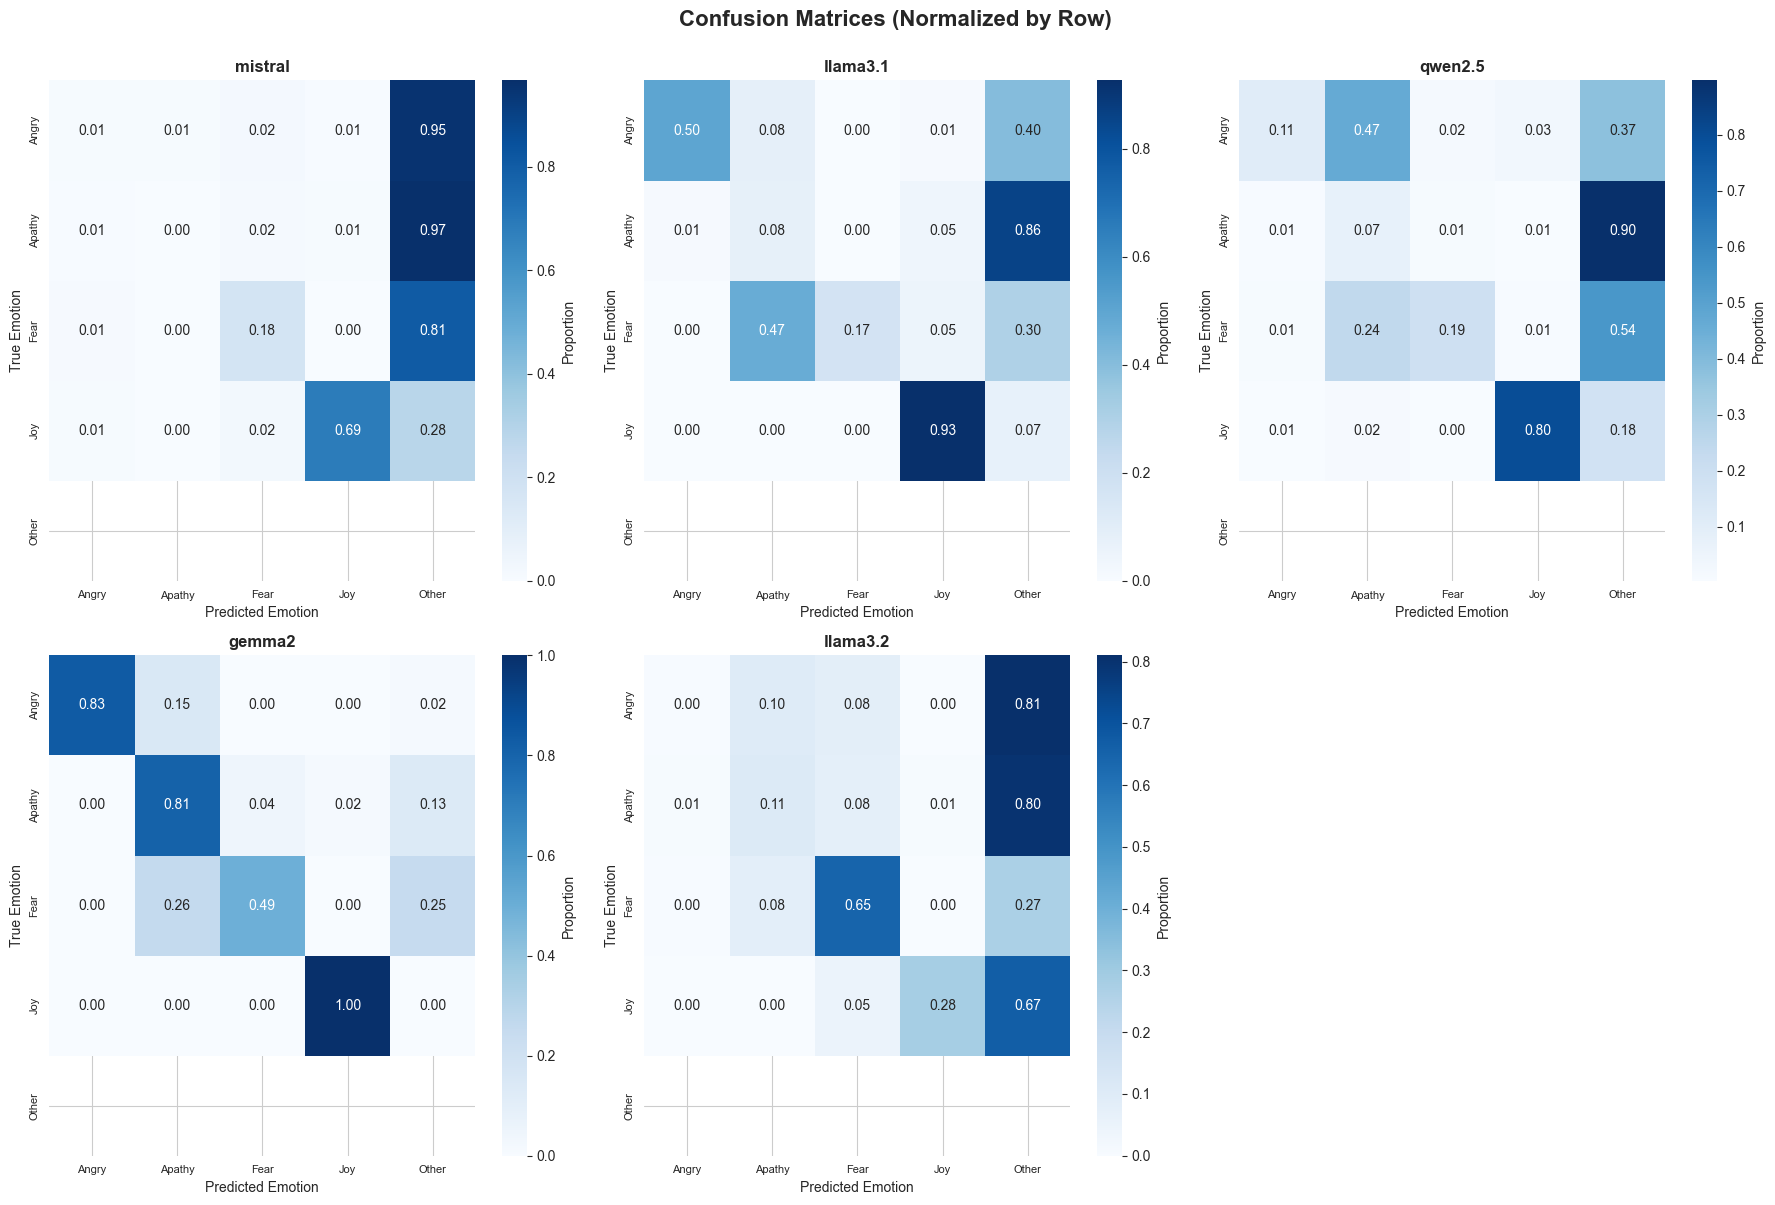

✓ Confusion matrices saved to: output/confusion_matrices.png


In [38]:
# Create confusion matrices for each model
emotion_labels = ['Apathy', 'Fear', 'Angry', 'Joy', 'Other', 'Error']

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for idx, model in enumerate(MODELS):
    model_name = model.split(':')[0].replace('.', '_')
    
    # Collect all predictions and expected values
    y_true = []
    y_pred = []
    
    for emotion_type in emotion_types:
        col_name = f"{model_name}_{emotion_type}"
        expected = emotion_mapping[emotion_type]
        
        y_true.extend([expected] * len(df))
        y_pred.extend(df[col_name].tolist())
    
    # Get all unique labels that appear in predictions
    all_labels = sorted(set(y_true + y_pred))
    
    # Create confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=all_labels)
    
    # Normalize by row (true labels)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    
    # Plot
    sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues', 
                xticklabels=all_labels, yticklabels=all_labels,
                ax=axes[idx], cbar_kws={'label': 'Proportion'})
    
    axes[idx].set_title(f'{model.split(":")[0]}', fontsize=12, fontweight='bold')
    axes[idx].set_ylabel('True Emotion', fontsize=10)
    axes[idx].set_xlabel('Predicted Emotion', fontsize=10)
    axes[idx].tick_params(axis='both', labelsize=8)

# Remove extra subplot if odd number of models
if len(MODELS) < len(axes):
    fig.delaxes(axes[-1])

plt.suptitle('Confusion Matrices (Normalized by Row)', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig(OUTPUT_PATH / 'confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Confusion matrices saved to: {OUTPUT_PATH / 'confusion_matrices.png'}")

### 3. Cohen's Kappa - Agreement Between Models

Misuriamo l'accordo tra i diversi modelli usando Cohen's Kappa.

In [39]:
# Calculate Cohen's Kappa between all pairs of models
from itertools import combinations

model_names = [m.split(':')[0].replace('.', '_') for m in MODELS]
n_models = len(model_names)

# Initialize matrix for kappa scores
kappa_matrix = np.zeros((n_models, n_models))

print("Cohen's Kappa Between Models:")
print("="*80)

for i, model1 in enumerate(model_names):
    for j, model2 in enumerate(model_names):
        if i == j:
            kappa_matrix[i, j] = 1.0
        elif i < j:
            # Collect all predictions for both models
            predictions1 = []
            predictions2 = []
            
            for emotion_type in emotion_types:
                col_name1 = f"{model1}_{emotion_type}"
                col_name2 = f"{model2}_{emotion_type}"
                
                predictions1.extend(df[col_name1].tolist())
                predictions2.extend(df[col_name2].tolist())
            
            # Calculate Cohen's Kappa
            kappa = cohen_kappa_score(predictions1, predictions2)
            kappa_matrix[i, j] = kappa
            kappa_matrix[j, i] = kappa
            
            print(f"{model1:15s} vs {model2:15s}: κ = {kappa:.4f}")

print("\n" + "="*80)

Cohen's Kappa Between Models:
mistral         vs llama3_1       : κ = 0.3980
mistral         vs qwen2_5        : κ = 0.4311
mistral         vs gemma2         : κ = 0.2205
mistral         vs llama3_2       : κ = 0.2436
llama3_1        vs qwen2_5        : κ = 0.4498
llama3_1        vs gemma2         : κ = 0.4254
llama3_1        vs llama3_2       : κ = 0.2504
qwen2_5         vs gemma2         : κ = 0.2713
qwen2_5         vs llama3_2       : κ = 0.2122
gemma2          vs llama3_2       : κ = 0.1428



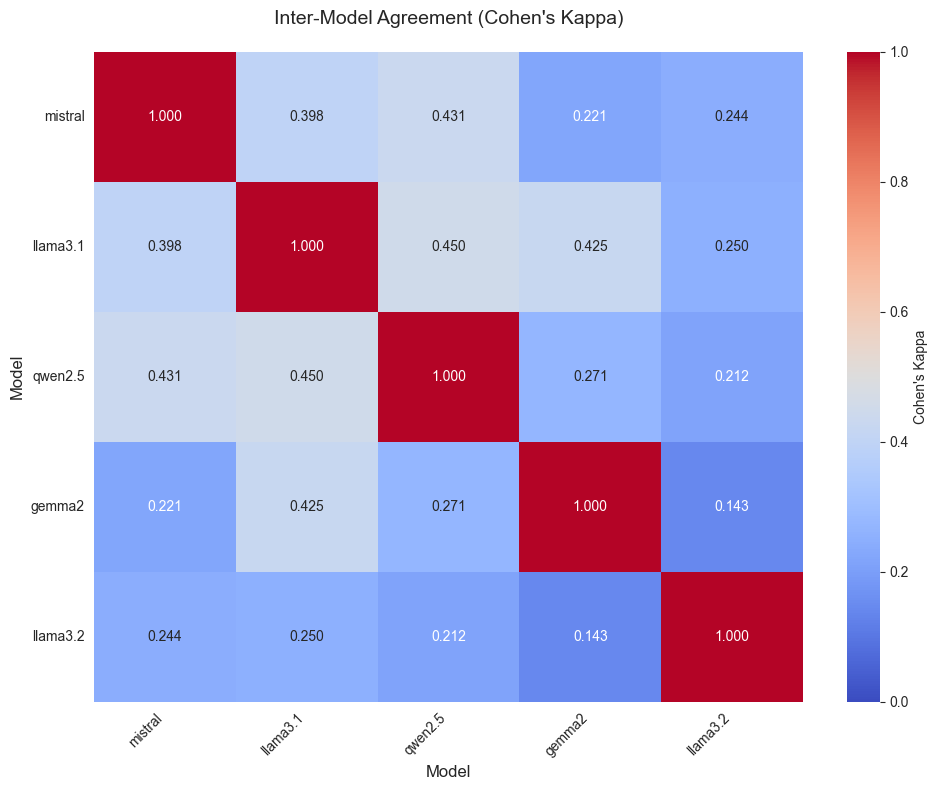

✓ Kappa matrix saved to: output/kappa_agreement.png

Interpretation of Cohen's Kappa:
  κ < 0.00: Poor agreement
  0.00 ≤ κ < 0.20: Slight agreement
  0.20 ≤ κ < 0.40: Fair agreement
  0.40 ≤ κ < 0.60: Moderate agreement
  0.60 ≤ κ < 0.80: Substantial agreement
  0.80 ≤ κ ≤ 1.00: Almost perfect agreement


In [50]:
# Visualize Kappa matrix
plt.figure(figsize=(10, 8))
sns.heatmap(kappa_matrix, annot=True, fmt='.3f', cmap='coolwarm', center=0.5,
            xticklabels=[m.replace('_', '.') for m in model_names],
            yticklabels=[m.replace('_', '.') for m in model_names],
            vmin=0, vmax=1, cbar_kws={'label': "Cohen's Kappa"})

plt.title("Inter-Model Agreement (Cohen's Kappa)", fontsize=14, pad=20)
plt.xlabel('Model', fontsize=12)
plt.ylabel('Model', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(OUTPUT_PATH / 'kappa_agreement.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Kappa matrix saved to: {OUTPUT_PATH / 'kappa_agreement.png'}")
print(f"\nInterpretation of Cohen's Kappa:")
print("  κ < 0.00: Poor agreement")
print("  0.00 ≤ κ < 0.20: Slight agreement")
print("  0.20 ≤ κ < 0.40: Fair agreement")
print("  0.40 ≤ κ < 0.60: Moderate agreement")
print("  0.60 ≤ κ < 0.80: Substantial agreement")
print("  0.80 ≤ κ ≤ 1.00: Almost perfect agreement")

### 4. Chi-Square Test

Test chi-quadrato per verificare se ci sono differenze significative nelle distribuzioni di classificazione tra i modelli.

In [41]:
# Chi-square test for each emotion type
print("Chi-Square Tests for Independence:")
print("="*80)

chi_square_results = {}

for emotion_type in emotion_types:
    print(f"\n{emotion_type.upper()} prompts:")
    print("-"*80)
    
    # Create contingency table
    contingency_table = []
    for model in MODELS:
        model_name = model.split(':')[0].replace('.', '_')
        col_name = f"{model_name}_{emotion_type}"
        
        # Count predictions for each emotion class
        value_counts = df[col_name].value_counts()
        contingency_table.append(value_counts)
    
    # Convert to DataFrame for easier manipulation
    contingency_df = pd.DataFrame(contingency_table)
    contingency_df = contingency_df.fillna(0).astype(int)
    
    # Perform chi-square test
    chi2, p_value, dof, expected = stats.chi2_contingency(contingency_df)
    
    chi_square_results[emotion_type] = {
        'chi2': chi2,
        'p_value': p_value,
        'dof': dof
    }
    
    print(f"  Chi-square statistic: {chi2:.4f}")
    print(f"  Degrees of freedom: {dof}")
    print(f"  P-value: {p_value:.6f}")
    
    if p_value < 0.001:
        print(f"  Result: HIGHLY SIGNIFICANT (p < 0.001) ***")
    elif p_value < 0.01:
        print(f"  Result: VERY SIGNIFICANT (p < 0.01) **")
    elif p_value < 0.05:
        print(f"  Result: SIGNIFICANT (p < 0.05) *")
    else:
        print(f"  Result: Not significant (p ≥ 0.05)")

print("\n" + "="*80)
print("\nConclusion:")
print("Se p < 0.05, rifiutiamo l'ipotesi nulla: le distribuzioni di classificazione")
print("tra i modelli sono significativamente diverse.")

Chi-Square Tests for Independence:

APATHETIC prompts:
--------------------------------------------------------------------------------
  Chi-square statistic: 874.9148
  Degrees of freedom: 16
  P-value: 0.000000
  Result: HIGHLY SIGNIFICANT (p < 0.001) ***

FEAR prompts:
--------------------------------------------------------------------------------
  Chi-square statistic: 578.3997
  Degrees of freedom: 16
  P-value: 0.000000
  Result: HIGHLY SIGNIFICANT (p < 0.001) ***

ANGER prompts:
--------------------------------------------------------------------------------
  Chi-square statistic: 1189.6719
  Degrees of freedom: 16
  P-value: 0.000000
  Result: HIGHLY SIGNIFICANT (p < 0.001) ***

JOY prompts:
--------------------------------------------------------------------------------
  Chi-square statistic: 535.7821
  Degrees of freedom: 16
  P-value: 0.000000
  Result: HIGHLY SIGNIFICANT (p < 0.001) ***


Conclusion:
Se p < 0.05, rifiutiamo l'ipotesi nulla: le distribuzioni di classifi

### 5. McNemar's Test

Test di McNemar per confrontare le performance tra coppie di modelli.

In [44]:
from statsmodels.stats.contingency_tables import mcnemar

# McNemar's test between pairs of models
print("McNemar's Test - Pairwise Model Comparison:")
print("="*80)

mcnemar_results = []

for i, model1 in enumerate(MODELS[:-1]):
    for model2 in MODELS[i+1:]:
        model_name1 = model1.split(':')[0].replace('.', '_')
        model_name2 = model2.split(':')[0].replace('.', '_')
        
        # Collect correct/incorrect for both models
        correct1 = []
        correct2 = []
        
        for emotion_type in emotion_types:
            col_name1 = f"{model_name1}_{emotion_type}"
            col_name2 = f"{model_name2}_{emotion_type}"
            expected = emotion_mapping[emotion_type]
            
            correct1.extend((df[col_name1] == expected).astype(int).tolist())
            correct2.extend((df[col_name2] == expected).astype(int).tolist())
        
        # Create contingency table
        # [[both correct, model1 correct & model2 incorrect],
        #  [model1 incorrect & model2 correct, both incorrect]]
        both_correct = sum((c1 == 1 and c2 == 1) for c1, c2 in zip(correct1, correct2))
        m1_correct_m2_incorrect = sum((c1 == 1 and c2 == 0) for c1, c2 in zip(correct1, correct2))
        m1_incorrect_m2_correct = sum((c1 == 0 and c2 == 1) for c1, c2 in zip(correct1, correct2))
        both_incorrect = sum((c1 == 0 and c2 == 0) for c1, c2 in zip(correct1, correct2))
        
        contingency = np.array([
            [both_correct, m1_correct_m2_incorrect],
            [m1_incorrect_m2_correct, both_incorrect]
        ])
        
        # Perform McNemar's test
        result = mcnemar(contingency, exact=False, correction=True)
        
        mcnemar_results.append({
            'model1': model1.split(':')[0],
            'model2': model2.split(':')[0],
            'statistic': result.statistic,
            'p_value': result.pvalue
        })
        
        print(f"\n{model1.split(':')[0]} vs {model2.split(':')[0]}:")
        print(f"  Statistic: {result.statistic:.4f}")
        print(f"  P-value: {result.pvalue:.6f}")
        
        if result.pvalue < 0.001:
            print(f"  Result: HIGHLY SIGNIFICANT difference (p < 0.001) ***")
        elif result.pvalue < 0.01:
            print(f"  Result: VERY SIGNIFICANT difference (p < 0.01) **")
        elif result.pvalue < 0.05:
            print(f"  Result: SIGNIFICANT difference (p < 0.05) *")
        else:
            print(f"  Result: No significant difference (p ≥ 0.05)")

print("\n" + "="*80)
print("\nConclusion:")
print("Se p < 0.05, i due modelli hanno performance significativamente diverse.")

McNemar's Test - Pairwise Model Comparison:

mistral vs llama3.1:
  Statistic: 232.3240
  P-value: 0.000000
  Result: HIGHLY SIGNIFICANT difference (p < 0.001) ***

mistral vs qwen2.5:
  Statistic: 51.1419
  P-value: 0.000000
  Result: HIGHLY SIGNIFICANT difference (p < 0.001) ***

mistral vs gemma2:
  Statistic: 676.0015
  P-value: 0.000000
  Result: HIGHLY SIGNIFICANT difference (p < 0.001) ***

mistral vs llama3.2:
  Statistic: 7.5075
  P-value: 0.006144
  Result: VERY SIGNIFICANT difference (p < 0.01) **

llama3.1 vs qwen2.5:
  Statistic: 93.6360
  P-value: 0.000000
  Result: HIGHLY SIGNIFICANT difference (p < 0.001) ***

llama3.1 vs gemma2:
  Statistic: 432.0205
  P-value: 0.000000
  Result: HIGHLY SIGNIFICANT difference (p < 0.001) ***

llama3.1 vs llama3.2:
  Statistic: 68.7619
  P-value: 0.000000
  Result: HIGHLY SIGNIFICANT difference (p < 0.001) ***

qwen2.5 vs gemma2:
  Statistic: 582.0822
  P-value: 0.000000
  Result: HIGHLY SIGNIFICANT difference (p < 0.001) ***

qwen2.5 v

### 6. Error Analysis

Analizziamo i pattern di errore più comuni.

In [45]:
# Analyze most common errors
print("Most Common Misclassifications:")
print("="*80)

for emotion_type in emotion_types:
    expected = emotion_mapping[emotion_type]
    
    print(f"\n{emotion_type.upper()} prompts (Expected: {expected}):")
    print("-"*80)
    
    # Collect all misclassifications across models
    misclassifications = {}
    
    for model in MODELS:
        model_name = model.split(':')[0].replace('.', '_')
        col_name = f"{model_name}_{emotion_type}"
        
        # Get incorrect predictions
        incorrect = df[df[col_name] != expected][col_name]
        
        for pred in incorrect:
            if pred not in misclassifications:
                misclassifications[pred] = 0
            misclassifications[pred] += 1
    
    # Sort by frequency
    sorted_errors = sorted(misclassifications.items(), key=lambda x: x[1], reverse=True)
    
    if sorted_errors:
        total_errors = sum(v for _, v in sorted_errors)
        print(f"  Total misclassifications: {total_errors} / {len(df) * len(MODELS)}")
        print(f"  Most common errors:")
        for pred, count in sorted_errors[:5]:
            percentage = (count / total_errors) * 100
            print(f"    Classified as '{pred}': {count} times ({percentage:.1f}% of errors)")
    else:
        print(f"  No misclassifications!")

print("\n" + "="*80)

Most Common Misclassifications:

APATHETIC prompts (Expected: Apathy):
--------------------------------------------------------------------------------
  Total misclassifications: 1179 / 1500
  Most common errors:
    Classified as 'Other': 1097 times (93.0% of errors)
    Classified as 'Fear': 45 times (3.8% of errors)
    Classified as 'Joy': 26 times (2.2% of errors)
    Classified as 'Angry': 11 times (0.9% of errors)

FEAR prompts (Expected: Fear):
--------------------------------------------------------------------------------
  Total misclassifications: 996 / 1500
  Most common errors:
    Classified as 'Other': 651 times (65.4% of errors)
    Classified as 'Apathy': 316 times (31.7% of errors)
    Classified as 'Joy': 20 times (2.0% of errors)
    Classified as 'Angry': 9 times (0.9% of errors)

ANGER prompts (Expected: Angry):
--------------------------------------------------------------------------------
  Total misclassifications: 1064 / 1500
  Most common errors:
    Class

### 7. Statistical Summary Report

Creiamo un report riassuntivo di tutte le statistiche calcolate.

In [46]:
# Create comprehensive statistical summary
summary_report = {
    'experiment_info': {
        'total_samples': len(df),
        'n_models': len(MODELS),
        'n_emotion_types': len(emotion_types),
        'total_classifications': len(df) * len(MODELS) * len(emotion_types)
    },
    'accuracy_results': accuracy_results,
    'chi_square_results': chi_square_results,
    'mcnemar_results': mcnemar_results,
    'kappa_matrix': kappa_matrix.tolist(),
    'model_names': model_names
}

# Save summary to JSON
import json
summary_path = OUTPUT_PATH / 'statistical_summary.json'
with open(summary_path, 'w') as f:
    json.dump(summary_report, f, indent=2)

print("Statistical Summary Report")
print("="*80)
print(f"\nExperiment Information:")
print(f"  Total samples: {summary_report['experiment_info']['total_samples']}")
print(f"  Number of models: {summary_report['experiment_info']['n_models']}")
print(f"  Emotion types: {summary_report['experiment_info']['n_emotion_types']}")
print(f"  Total classifications: {summary_report['experiment_info']['total_classifications']}")

print(f"\nBest Performing Model (Overall Accuracy):")
best_model = max(accuracy_results.items(), key=lambda x: x[1]['overall'])
print(f"  {best_model[0].replace('_', '.')}: {best_model[1]['overall']:.2f}%")

print(f"\nAverage Inter-Model Agreement (Cohen's Kappa):")
# Get upper triangle of kappa matrix (excluding diagonal)
kappa_values = []
for i in range(len(kappa_matrix)):
    for j in range(i+1, len(kappa_matrix)):
        kappa_values.append(kappa_matrix[i, j])
avg_kappa = np.mean(kappa_values)
print(f"  Mean κ: {avg_kappa:.4f}")

print(f"\n✓ Full statistical report saved to: {summary_path}")
print("="*80)

Statistical Summary Report

Experiment Information:
  Total samples: 300
  Number of models: 5
  Emotion types: 4
  Total classifications: 6000

Best Performing Model (Overall Accuracy):
  gemma2: 78.33%

Average Inter-Model Agreement (Cohen's Kappa):
  Mean κ: 0.3045

✓ Full statistical report saved to: output/statistical_summary.json


### 8. Dataset-Specific Analysis

Analizziamo le performance per ogni dataset separatamente.

In [ ]:
# Analyze accuracy by dataset
print("Accuracy by Dataset:")
print("="*80)

dataset_accuracies = {}

for dataset_name in df['dataset'].unique():
    dataset_df = df[df['dataset'] == dataset_name]
    
    print(f"\n{dataset_name}:")
    print("-"*80)
    
    dataset_accuracies[dataset_name] = {}
    
    for model in MODELS:
        model_name = model.split(':')[0].replace('.', '_')
        
        total_correct = 0
        total_samples = 0
        
        for emotion_type in emotion_types:
            col_name = f"{model_name}_{emotion_type}"
            expected = emotion_mapping[emotion_type]
            
            correct = (dataset_df[col_name] == expected).sum()
            total = len(dataset_df)
            
            total_correct += correct
            total_samples += total
        
        accuracy = (total_correct / total_samples) * 100
        dataset_accuracies[dataset_name][model_name] = accuracy
        
        print(f"  {model.split(':')[0]:20s}: {accuracy:.2f}%")

print("\n" + "="*80)

# Visualize dataset-specific accuracies
datasets = list(dataset_accuracies.keys())
fig, ax = plt.subplots(figsize=(14, 6))

x = np.arange(len(datasets))
width = 0.15

for i, model in enumerate(MODELS):
    model_name = model.split(':')[0].replace('.', '_')
    accuracies = [dataset_accuracies[ds][model_name] for ds in datasets]
    offset = width * (i - 2)
    ax.bar(x + offset, accuracies, width, label=model.split(':')[0])

ax.set_xlabel('Dataset', fontsize=12)
ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_title('Model Accuracy by Dataset', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(datasets, rotation=45, ha='right')
ax.set_ylim(0, 100)
ax.legend(title='Model', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_PATH / 'dataset_accuracy.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Dataset accuracy plot saved to: {OUTPUT_PATH / 'dataset_accuracy.png'}")